# Model distillation: teaching a tiny local model to classify search queries

**The idea.** A big LLM is good at classifying search queries by intent, but every call costs money and takes most of a second. So we let the big model act as a **teacher**: it labels a batch of queries once, and a **student** network with about 50,000 parameters learns to copy its answers. After that, the student runs on your own machine in milliseconds, for free, with no API.

**What this notebook does**
1. The **teacher** (`gpt-oss-120b`, an open-weight LLM) gives a probability for each of 5 intents for about 120 search queries.
2. Each query becomes a 384-number vector (sentence embedding).
3. The **student** (384 → 128 → 5) is trained to match the teacher's probabilities, using **KL divergence** as the loss.
4. We measure how often the student agrees with the teacher **on queries it never saw in training**, how close the probabilities are (Jensen-Shannon distance), and the speed and cost of each.
5. We check whether **soft labels** (the full probabilities) beat **hard labels** (only the top intent).

**Before you run it**
- Needs `CEREBRAS_API_KEY` (or `GROQ_API_KEY`) in a `.env` file at the repository root (see the README).
- The first run makes about 125 teacher calls (roughly 45,000 tokens) and saves the labels to `teacher_labels.json` next to this notebook. Later runs reuse that file, so only the 8 live example calls cost tokens. Delete the file to ask the teacher again.
- Training runs on the CPU in a few seconds.

In [1]:
import json
import os
import time
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")  # keep the model-loading bars out of the output
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")  # hides the "unauthenticated requests" notice

warnings.filterwarnings("ignore", message="IProgress not found")  # harmless notice from tqdm

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from dotenv import load_dotenv
from openai import OpenAI
from scipy.spatial.distance import jensenshannon

load_dotenv()  # finds the .env file at the repository root (it searches parent folders)

# Teacher: gpt-oss-120b on Cerebras if that key is set, otherwise on Groq (both speak the OpenAI API).
if os.getenv("CEREBRAS_API_KEY"):
    PROVIDER, MODEL = "Cerebras", "gpt-oss-120b"
    client = OpenAI(base_url="https://api.cerebras.ai/v1", api_key=os.environ["CEREBRAS_API_KEY"], max_retries=10)
elif os.getenv("GROQ_API_KEY"):
    PROVIDER, MODEL = "Groq", "openai/gpt-oss-120b"
    client = OpenAI(base_url="https://api.groq.com/openai/v1", api_key=os.environ["GROQ_API_KEY"], max_retries=10)
else:
    raise RuntimeError("Put CEREBRAS_API_KEY or GROQ_API_KEY in a .env file at the repository root.")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
LABELS_FILE = Path("teacher_labels.json")
print(f"Teacher: {MODEL} on {PROVIDER}")

Teacher: gpt-oss-120b on Cerebras


## 1. The task: five query intents

Before routing a query (to search, a product page, a help desk…), a shop's search box first decides what kind of query it is:

| Intent | Meaning | Example |
|---|---|---|
| navigational | wants to reach a specific site, page or store | "amazon login" |
| informational | wants to learn how or what something is | "how does a microwave work" |
| transactional | wants to buy, book, order or subscribe | "buy iphone 15 pro" |
| comparison | is weighing two or more options | "nike vs adidas running shoes" |
| support | needs help with an order, account or product problem | "track my order" |

The queries below are **unlabelled**. We never write down the right answer ourselves; the teacher provides the labels. That is one of distillation's selling points: you need realistic inputs and access to a good teacher, not hand-labelled data.

In [2]:
INTENTS = ["navigational", "informational", "transactional", "comparison", "support"]

QUERIES = [
    # mostly navigational
    "amazon login", "walmart store locator", "gmail sign in", "netflix account page", "best buy near me",
    "target weekly ad", "ikea website", "youtube studio", "apple support website", "home depot hours",
    "costco membership page", "nike official site", "ebay my orders", "facebook marketplace", "linkedin jobs",
    "chase bank login", "spotify web player", "zara online store", "wikipedia", "outlook mail",
    "ups tracking page", "github",
    # mostly informational
    "how does noise cancellation work", "how does a microwave work", "what is oled", "how many watts does a fridge use",
    "why is my phone battery draining fast", "what size tv for living room", "how to clean a cast iron pan",
    "how long do air fryers last", "what does hdr mean", "is coffee bad for you", "how to choose running shoes",
    "what is a mechanical keyboard", "how do heat pumps work", "benefits of a standing desk",
    "best temperature for a fridge", "how to fold a fitted sheet", "what is bluetooth 5.3",
    "how does wireless charging work", "how many calories in a banana", "what is a mesh wifi system",
    "how to measure ring size", "what does spf mean", "how to descale a kettle", "what is memory foam",
    "history of the iphone",
    # mostly transactional
    "buy iphone 15 pro", "coffee maker", "target gift card balance", "cheap noise cancelling headphones",
    "order pizza online", "airpods pro discount", "book flight to new york", "samsung tv deals",
    "buy running shoes size 10", "nike air max sale", "best price ps5", "ikea kallax shelf", "laptop under 500 dollars",
    "subscribe to netflix", "rent a car in miami", "dyson vacuum coupon code", "kindle paperwhite",
    "4k monitor 27 inch", "organic coffee beans 1kg", "standing desk free shipping", "pre order galaxy s25",
    "cheap flights to london", "instant pot", "lego star wars set", "electric toothbrush offer",
    # mostly comparison
    "what is the difference between led and oled", "nike vs adidas running shoes", "samsung vs iphone camera",
    "iphone 15 vs iphone 16", "kindle vs kobo", "ps5 vs xbox series x", "air fryer or convection oven",
    "mac or windows laptop for students", "dyson v15 vs shark", "spotify vs apple music",
    "canon vs nikon beginner camera", "gas vs electric stove", "airpods pro vs sony wf-1000xm5",
    "costco vs sam's club", "which is better ssd or hdd", "memory foam vs spring mattress",
    "netflix vs disney plus price", "android vs ios", "electric vs manual toothbrush", "uber vs lyft",
    "mesh wifi vs extender", "roomba vs roborock",
    # mostly support
    "track my order", "return a damaged item", "reset my router password", "app keeps crashing",
    "cancel my subscription", "refund not received", "how to contact amazon customer service",
    "package says delivered but not here", "change delivery address", "laptop won't turn on", "forgot my password",
    "warranty claim for broken headphones", "wrong item delivered", "printer not connecting to wifi",
    "charged twice for my order", "update payment method", "my airpods won't pair", "order stuck in processing",
    "how do i return shoes to nike", "account locked", "dishwasher not draining", "promo code not working",
]
assert len(QUERIES) == len(set(QUERIES))
print(f"{len(QUERIES)} unlabelled queries (the comments above are only for reading; the code never uses them)")

116 unlabelled queries (the comments above are only for reading; the code never uses them)


## 2. The teacher

The prompt does three jobs:
- it asks for a **probability for every intent**, not just one answer;
- it says the probabilities **must sum to 1**;
- it asks for **JSON in a fixed shape**, so code can read it. `response_format={"type": "json_object"}` makes the API return valid JSON.

The code still checks the reply: every intent must be present, negative values are cut to 0, and the five numbers are rescaled to sum to exactly 1 (models often reply with sums like 0.99 or 1.01). A reply that fails the check is asked again, up to 3 times.

In [3]:
PROMPT = """Analyze the search query and return a probability score for each intent category. The probabilities must sum to 1.

Intent categories:
- navigational: the user wants to reach a specific website, page or store
- informational: the user wants to learn how or what something is
- transactional: the user wants to buy, book, order or subscribe to something
- comparison: the user is weighing two or more options against each other
- support: the user needs help with an order, account or product problem

Query: {query}

Return only JSON exactly in this form:
{{"navigational": 0.0, "informational": 0.0, "transactional": 0.0, "comparison": 0.0, "support": 0.0}}"""


def get_intent_probabilities(query: str) -> dict:
    """Ask the teacher for one probability per intent. Also records the call's latency and tokens."""
    for _ in range(3):
        start = time.perf_counter()
        response = client.chat.completions.create(
            model=MODEL,
            messages=[{"role": "user", "content": PROMPT.format(query=query)}],
            temperature=0,
            max_tokens=1024,          # gpt-oss thinks before answering, and the thinking uses this budget too
            reasoning_effort="low",
            response_format={"type": "json_object"},
        )
        latency = time.perf_counter() - start
        try:
            raw = json.loads(response.choices[0].message.content)
            probs = np.array([max(float(raw[intent]), 0.0) for intent in INTENTS])
            if probs.sum() <= 0:
                raise ValueError("all probabilities are zero")
        except (json.JSONDecodeError, KeyError, TypeError, ValueError):
            continue  # malformed reply: ask again
        return {
            "query": query,
            **{intent: float(p) for intent, p in zip(INTENTS, probs / probs.sum())},
            "reply_sum": float(probs.sum()),  # what the teacher's numbers added up to before rescaling
            "latency_s": latency,
            "prompt_tokens": response.usage.prompt_tokens,
            "completion_tokens": response.usage.completion_tokens,
        }
    raise RuntimeError(f"The teacher gave no usable JSON for {query!r}")


# Two quick checks (live calls)
for q in ["Samsung vs iPhone camera", "How does a microwave work?"]:
    row = get_intent_probabilities(q)
    print(f"{q:28s}", "  ".join(f"{i} {row[i]:.0%}" for i in INTENTS), f"  ({row['latency_s'] * 1000:.0f} ms)")

Samsung vs iPhone camera     navigational 2%  informational 20%  transactional 3%  comparison 70%  support 5%   (686 ms)
How does a microwave work?   navigational 2%  informational 94%  transactional 1%  comparison 2%  support 1%   (654 ms)


Now the teacher labels every query. This is the expensive step, so it runs once and the result is saved.

In [4]:
if LABELS_FILE.exists():
    teacher_rows = json.loads(LABELS_FILE.read_text(encoding="utf-8"))
    print(f"Loaded {len(teacher_rows)} saved teacher labels from {LABELS_FILE} (delete it to ask the teacher again).")
else:
    teacher_rows = []
    for n, q in enumerate(QUERIES, 1):
        teacher_rows.append(get_intent_probabilities(q))
        if n % 30 == 0 or n == len(QUERIES):
            print(f"  labelled {n}/{len(QUERIES)}")
    LABELS_FILE.write_text(json.dumps(teacher_rows, indent=1), encoding="utf-8")
    print(f"Saved the teacher's labels to {LABELS_FILE}")
assert [r["query"] for r in teacher_rows] == QUERIES, "The saved labels belong to a different query list: delete the file."

df = pd.DataFrame(teacher_rows)
lat_ms = df["latency_s"] * 1000
print(f"\nTeacher latency per query: mean {lat_ms.mean():.0f} ms, median {lat_ms.median():.0f} ms, "
      f"95th percentile {lat_ms.quantile(0.95):.0f} ms")
print(f"Tokens per query: {df.prompt_tokens.mean():.0f} in + {df.completion_tokens.mean():.0f} out "
      f"(the output includes the model's hidden reasoning)")
off = (df.reply_sum - 1).abs() > 0.005
print(f"Replies whose probabilities did not add up to 1: {off.sum()} of {len(df)} (rescaled)")
df[["query"] + INTENTS].head(8).round(2)

Loaded 116 saved teacher labels from teacher_labels.json (delete it to ask the teacher again).

Teacher latency per query: mean 482 ms, median 471 ms, 95th percentile 647 ms
Tokens per query: 256 in + 99 out (the output includes the model's hidden reasoning)
Replies whose probabilities did not add up to 1: 0 of 116 (rescaled)


,query,navigational,informational,transactional,comparison,support
0,amazon login,0.80,0.05,0.00,0.00,0.15
1,walmart store locator,0.86,0.09,0.02,0.02,0.01
2,gmail sign in,0.85,0.10,0.00,0.00,0.05
3,netflix account page,0.85,0.05,0.00,0.00,0.10
4,best buy near me,0.88,0.09,0.02,0.01,0.00
5,target weekly ad,0.60,0.30,0.05,0.03,0.02
6,ikea website,0.85,0.10,0.02,0.02,0.01
7,youtube studio,0.72,0.22,0.02,0.02,0.02


## 3. Soft labels vs hard labels

- A **hard label** keeps only the top intent: "coffee maker → transactional".
- A **soft label** keeps all five probabilities: "coffee maker → 40% informational, 40% transactional, 15% comparison…".

The case for soft labels: they carry **nuance**. Some queries really are a bit of two things, and the probabilities also tell the student how sure the teacher was. Below: how the top intents are spread, and the queries the teacher was least sure about.

In [5]:
df["top_intent"] = df[INTENTS].idxmax(axis=1)  # on a tie, the first intent in the list wins
df["top_prob"] = df[INTENTS].max(axis=1)
print("Top intent per query (hard labels):")
print(df["top_intent"].value_counts().reindex(INTENTS).to_string())
print(f"\nQueries where the teacher's top intent got less than 60%: {(df.top_prob < 0.6).sum()} of {len(df)}")
df.sort_values("top_prob")[["query"] + INTENTS].head(8).round(2)

Top intent per query (hard labels):
top_intent
navigational     18
informational    36
transactional    16
comparison       22
support          24

Queries where the teacher's top intent got less than 60%: 9 of 116


,query,navigational,informational,transactional,comparison,support
63,kindle paperwhite,0.15,0.4,0.35,0.07,0.03
48,coffee maker,0.05,0.4,0.40,0.15,0.00
50,cheap noise cancelling headphones,0.05,0.3,0.40,0.25,0.00
64,4k monitor 27 inch,0.05,0.4,0.30,0.20,0.05
69,instant pot,0.10,0.4,0.40,0.05,0.05
70,lego star wars set,0.10,0.4,0.40,0.10,0.00
59,laptop under 500 dollars,0.00,0.4,0.50,0.10,0.00
14,linkedin jobs,0.40,0.5,0.05,0.03,0.02


**What this shows:** most queries get one clear intent. The 9 unsure ones are mostly product names with no verb ("coffee maker", "instant pot", "kindle paperwhite"): does the user want to buy it or learn about it? That is the nuance soft labels keep. The numbers are coarse, though: mostly round figures like 5%, 40% or 85%, with ties like 40/40.

## 4. Held-out test set and embeddings

**A fair test.** Measuring agreement on the same queries the student trained on would flatter it. Here a quarter of the queries are held out: the student never trains on them, and the headline numbers come from them.

**Embeddings.** A neural network can't read text, so each query becomes a 384-number vector from the sentence-transformer `all-MiniLM-L6-v2`. That encoder is frozen and does the language understanding; the student only has to learn the small step from "meaning vector" to "intent".

In [6]:
from sentence_transformers import SentenceTransformer

order = np.random.default_rng(SEED).permutation(len(df))
n_test = len(df) // 4
test_idx, train_idx = np.sort(order[:n_test]), np.sort(order[n_test:])
print(f"Training queries: {len(train_idx)}   held-out test queries: {len(test_idx)}")
print("Test set by the teacher's top intent:", df.loc[test_idx, "top_intent"].value_counts().reindex(INTENTS).to_dict())

encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
X = torch.tensor(encoder.encode(QUERIES), dtype=torch.float32)   # (queries, 384)
P = torch.tensor(df[INTENTS].values, dtype=torch.float32)        # teacher's soft labels, (queries, 5)
print(f"\nEmbeddings: {tuple(X.shape)}   teacher labels: {tuple(P.shape)}")

Training queries: 87   held-out test queries: 29
Test set by the teacher's top intent: {'navigational': 6, 'informational': 7, 'transactional': 3, 'comparison': 7, 'support': 6}

Embeddings: (116, 384)   teacher labels: (116, 5)


## 5. The student

One hidden layer: 384 inputs → 128 neurons (ReLU) → 5 outputs, one per intent. A softmax turns the 5 outputs into probabilities. That is 384×128 + 128 + 128×5 + 5 = **49,925** parameters.

In [7]:
def make_student():
    torch.manual_seed(SEED)  # same starting weights every time, so runs are comparable
    return nn.Sequential(nn.Linear(384, 128), nn.ReLU(), nn.Linear(128, len(INTENTS)))


student = make_student()
n_student = sum(p.numel() for p in student.parameters())
n_encoder = sum(p.numel() for p in encoder.parameters())
print(f"Student parameters: {n_student:,}")
print(f"Encoder parameters: {n_encoder:,} (frozen, but it also has to run on every query)")

Student parameters: 49,925
Encoder parameters: 22,713,216 (frozen, but it also has to run on every query)


## 6. The loss: KL divergence, with a temperature

**KL divergence** measures how far the student's probabilities are from the teacher's:

$$D_{KL}(P \,\|\, Q) = \sum_i P(i) \log \frac{P(i)}{Q(i)}$$

with $P$ = teacher and $Q$ = student. It is 0 when they match exactly and grows as they drift apart. Training pushes the student's **whole** distribution towards the teacher's, not just its top pick.

**Temperature (T = 3)** flattens both distributions before comparing them. That makes the small probabilities ("10% support") count for more, so the student learns more than just the winner. The loss is multiplied by T² to keep the size of the training steps about the same as without a temperature.

The teacher gives probabilities rather than raw scores, so its distribution is flattened by taking the log of each probability, dividing by T and applying softmax again. One catch: the log of 0 is minus infinity, so very small values need a **floor**. The teacher writes its probabilities in steps of 1% or more, so anything below 1% is treated as 1%. A tiny floor such as 0.0001 made "0%" and "1%" look very different after flattening. In testing, that noise cut held-out agreement from about 69% to about 61%.

In [8]:
T = 3.0
FLOOR = 0.01  # the teacher's numbers are only precise to about 1%


def soften(probs, T):
    """Flatten a probability distribution with temperature T (T=1 leaves it unchanged)."""
    return torch.softmax(torch.log(probs.clamp_min(FLOOR)) / T, dim=-1)


def distillation_loss(student_logits, teacher_probs):
    student_log_probs = F.log_softmax(student_logits / T, dim=-1)  # PyTorch's KL wants log-probabilities
    return F.kl_div(student_log_probs, soften(teacher_probs, T), reduction="batchmean") * T * T


example = P[QUERIES.index("amazon login")]
print("amazon login, teacher:          ", np.round(example.numpy(), 3))
print("amazon login, flattened at T=3: ", np.round(soften(example, T).numpy(), 3))

amazon login, teacher:           [0.8  0.05 0.   0.   0.15]
amazon login, flattened at T=3:  [0.411 0.163 0.095 0.095 0.235]


## 7. Training

Adam, learning rate 0.001, batch size 16 and **60 epochs**: at 25 epochs the loss was still falling, and it levels off by about epoch 60. After each epoch we also check agreement on the held-out queries.

Trained in 0.6 s
 epoch  train_loss  test_agreement
     1       1.501           0.276
    10       0.926           0.241
    25       0.164           0.690
    40       0.053           0.724
    60       0.015           0.724


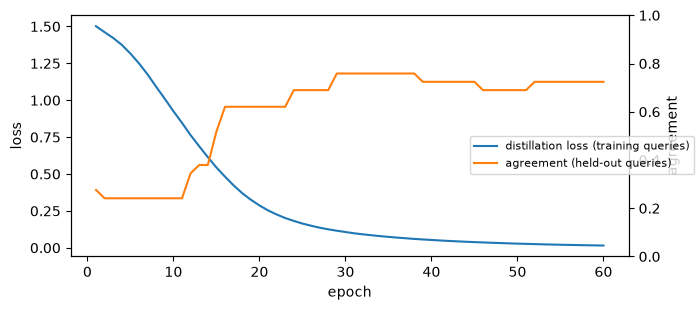

In [9]:
@torch.no_grad()
def predict_probs(model, idx):
    model.eval()
    return torch.softmax(model(X[idx]), dim=-1).numpy()


def agreement(model, idx):
    """Share of queries where the student's top intent is the teacher's top intent."""
    return float((predict_probs(model, idx).argmax(1) == P[idx].numpy().argmax(1)).mean())


def train(model, loss_fn, targets, epochs=60, batch_size=16, lr=1e-3, train_on=None, test_on=None):
    train_on = train_idx if train_on is None else train_on
    test_on = test_idx if test_on is None else test_on
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    shuffler = torch.Generator().manual_seed(SEED)
    train_t = torch.tensor(train_on)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for batch in train_t[torch.randperm(len(train_t), generator=shuffler)].split(batch_size):
            loss = loss_fn(model(X[batch]), targets[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        history.append({"epoch": epoch, "train_loss": total / len(train_t), "test_agreement": agreement(model, test_on)})
    return pd.DataFrame(history)


start = time.perf_counter()
history = train(student, distillation_loss, P)
print(f"Trained in {time.perf_counter() - start:.1f} s")
print(history.iloc[[0, 9, 24, 39, 59]].round(3).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(7, 3.2))
ax1.plot(history.epoch, history.train_loss, label="distillation loss (training queries)")
ax1.set_xlabel("epoch")
ax1.set_ylabel("loss")
ax2 = ax1.twinx()
ax2.plot(history.epoch, history.test_agreement, color="tab:orange", label="agreement (held-out queries)")
ax2.set_ylabel("agreement")
ax2.set_ylim(0, 1)
fig.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()

## 8. How well does the student copy the teacher?

Two measures:
- **Top-1 agreement:** how often the student's top intent matches the teacher's.
- **Jensen-Shannon distance:** how close the full probability lists are. 0 means identical and 1 means completely different. Unlike KL, it is symmetric and has an upper limit, which makes it easier to read.

Note that both measures compare the student with the **teacher**, not with the truth. If the teacher is wrong, a perfect student is wrong too.

Both are shown for the training queries (the flattering number) and for the held-out queries (the honest number).

In [10]:
def evaluate(model, idx):
    q, p = predict_probs(model, idx), P[idx].numpy()
    js = np.mean([jensenshannon(pi, qi, base=2) for pi, qi in zip(p, q)])
    return (q.argmax(1) == p.argmax(1)).mean(), js


majority = df.loc[train_idx, "top_intent"].mode()[0]
baseline = (df.loc[test_idx, "top_intent"] == majority).mean()
for name, idx in [("training queries", train_idx), ("held-out queries", test_idx)]:
    agree, js = evaluate(student, idx)
    print(f"{name:17s} agreement {agree:.0%}   Jensen-Shannon distance {js:.3f}")
print(f"(For scale: always answering '{majority}', the most common intent, agrees on {baseline:.0%} of held-out queries.)")

q_test = predict_probs(student, test_idx)
table = pd.DataFrame({
    "query": df.loc[test_idx, "query"].values,
    "teacher": [f"{INTENTS[i]} {p:.0%}" for i, p in zip(P[test_idx].numpy().argmax(1), P[test_idx].numpy().max(1))],
    "student": [f"{INTENTS[i]} {p:.0%}" for i, p in zip(q_test.argmax(1), q_test.max(1))],
})
table["match"] = np.where(P[test_idx].numpy().argmax(1) == q_test.argmax(1), "yes", "NO")
print("\nHeld-out queries where the student and the teacher disagree:")
table[table.match == "NO"]

training queries  agreement 98%   Jensen-Shannon distance 0.081
held-out queries  agreement 72%   Jensen-Shannon distance 0.326
(For scale: always answering 'informational', the most common intent, agrees on 24% of held-out queries.)

Held-out queries where the student and the teacher disagree:


,query,teacher,student,match
3,best buy near me,navigational 88%,transactional 38%,NO
4,wikipedia,navigational 70%,informational 62%,NO
12,cheap noise cancelling headphones,transactional 40%,informational 55%,NO
14,buy running shoes size 10,transactional 88%,informational 68%,NO
15,nike air max sale,transactional 70%,informational 40%,NO
20,netflix vs disney plus price,comparison 80%,transactional 37%,NO
22,electric vs manual toothbrush,comparison 80%,informational 48%,NO
28,promo code not working,support 90%,transactional 28%,NO


**What this shows**
- **On its training queries the student looks almost perfect:** 98% agreement, Jensen-Shannon distance 0.08. That is the number you get by testing on the training data.
- **On queries it never saw, it agrees 72% of the time** (distance 0.33). With only 87 training queries, the student partly memorises them, so held-out queries are the honest test.
- **Most misses are short queries** where the student falls back on informational or transactional: "wikipedia", "best buy near me", "promo code not working", even "buy running shoes size 10".
- It is still far better than guessing: always answering "informational" agrees only 24% of the time.

## 9. Speed and cost

- The **teacher's** time is what each labelling call took (network included).
- The **student's** time is the full local path for one query: embed it, then run the small network. The network alone is also timed.
- Cost uses the real token counts from the labelling calls, priced at example rates. **Check your provider's current prices** and change `PRICE_PER_M` to match.

In [11]:
student.eval()


def classify(query: str) -> dict:
    """The deployed student: query text in, intent probabilities out. Runs locally, no API."""
    with torch.no_grad():
        x = torch.tensor(encoder.encode([query]), dtype=torch.float32)
        probs = torch.softmax(student(x), dim=-1)[0].numpy()
    return {intent: float(p) for intent, p in zip(INTENTS, probs)}


classify("warm-up")  # the first call pays one-off start-up costs
student_ms = []
for q in df.loc[test_idx, "query"]:
    start = time.perf_counter()
    classify(q)
    student_ms.append((time.perf_counter() - start) * 1000)
x1 = X[test_idx[:1]]
with torch.no_grad():
    start = time.perf_counter()
    for _ in range(1000):
        student(x1)
head_ms = (time.perf_counter() - start)  # 1000 runs, so seconds = ms per run

teacher_ms = df["latency_s"].median() * 1000
print(f"Teacher (API call):          median {teacher_ms:6.0f} ms per query")
print(f"Student (embed + network):   median {np.median(student_ms):6.1f} ms per query  "
      f"-> about {teacher_ms / np.median(student_ms):.0f}x faster")
print(f"Student network alone:              {head_ms:.3f} ms per query")

PRICE_PER_M = {"input": 0.35, "output": 0.75}  # USD per million tokens: EXAMPLE rates, check your provider
cost_per_1k = 1000 * (df.prompt_tokens.mean() * PRICE_PER_M["input"]
                      + df.completion_tokens.mean() * PRICE_PER_M["output"]) / 1e6
print(f"\nTeacher cost: about ${cost_per_1k:.3f} per 1,000 queries at the example rates "
      f"(${cost_per_1k * 1000:.0f} per million queries)")
print("Student cost: no API fee; it runs on hardware you already have")

Teacher (API call):          median    471 ms per query
Student (embed + network):   median   12.1 ms per query  -> about 39x faster
Student network alone:              0.044 ms per query

Teacher cost: about $0.164 per 1,000 queries at the example rates ($164 per million queries)
Student cost: no API fee; it runs on hardware you already have


**What this shows**
- **The student answers in about 12 ms instead of 471 ms**, about 40 times faster (timings depend on the machine).
- **Almost all of the student's time is the sentence encoder.** The 50,000-parameter network itself takes 0.04 ms. So "tiny" describes the student network, but deploying it also means shipping the 22.7-million-parameter encoder (about 90 MB), which still runs fine on an ordinary CPU.
- **At the example rates the teacher costs about $0.16 per 1,000 queries.** That is small per query, but at a million queries a day it is about $164 a day, plus half a second of waiting on every query.

## 10. Do soft labels actually help?

Same student and settings, trained three ways:
- **soft labels, T = 3**: the setup above;
- **soft labels, T = 1**: the teacher's probabilities as they are, no flattening;
- **hard labels**: only the teacher's top intent (plain cross-entropy loss), as if the probabilities had been thrown away.

With only 29 held-out queries, one query is worth 3.4 points of agreement, so a single split is too noisy to compare methods. Instead this uses **4-fold cross-validation, repeated with 3 different shuffles**. Every query is held out once per shuffle, and each method's score is the average over 12 trainings (about 30 seconds in total).

In [12]:
METHODS = {
    "soft labels, T=3": distillation_loss,
    "soft labels, T=1": lambda logits, probs: F.kl_div(F.log_softmax(logits, dim=-1), probs, reduction="batchmean"),
    "hard labels (top intent)": lambda logits, probs: F.cross_entropy(logits, probs.argmax(dim=-1)),
}
scores = {name: [] for name in METHODS}
for shuffle in range(3):
    folds = np.array_split(np.random.default_rng(shuffle).permutation(len(df)), 4)
    for k in range(4):
        held_out = np.sort(folds[k])
        trained_on = np.sort(np.concatenate([f for j, f in enumerate(folds) if j != k]))
        for name, loss_fn in METHODS.items():
            model = make_student()
            train(model, loss_fn, P, train_on=trained_on, test_on=held_out)
            scores[name].append(evaluate(model, held_out))

pd.DataFrame([{"student trained on": name,
               "held-out agreement": f"{np.mean([a for a, _ in s]):.0%}",
               "Jensen-Shannon distance": round(float(np.mean([j for _, j in s])), 3)}
              for name, s in scores.items()])

,student trained on,held-out agreement,Jensen-Shannon distance
0,"soft labels, T=3",70%,0.347
1,"soft labels, T=1",72%,0.341
2,hard labels (top intent),77%,0.342


**What this shows:** in this test, soft labels did **not** beat hard labels.
- Hard labels did a little better on top-1 agreement (77% against 70-72%).
- All three methods are level on the Jensen-Shannon distance (0.34-0.35).

Likely reasons:
- **The teacher's probabilities are written guesses,** mostly round figures with ties like 40/40. They are not the model's real internal probabilities, which is what classic distillation uses and where the extra nuance lives.
- **The data is tiny** (87 training queries per fold), so every method partly memorises.
- **Top-1 agreement rewards picking the winner,** which is exactly what hard labels train for.

This small test can't say whether soft labels would win with thousands of real queries.

## 11. Using the student

Queries that appear nowhere above, classified by the student locally and, for comparison, by the teacher with live API calls.

In [13]:
NEW_QUERIES = [
    "sony wh-1000xm5 vs bose qc ultra",
    "how do i get a refund for a late delivery",
    "best buy login",
    "buy dyson airwrap",
    "what is a heat pump dryer",
    "cheap gaming chair",
]
rows = []
for q in NEW_QUERIES:
    s = classify(q)
    t = get_intent_probabilities(q)
    s_top, t_top = max(s, key=s.get), max(INTENTS, key=lambda i: t[i])
    rows.append({"query": q, "student": f"{s_top} {s[s_top]:.0%}", "teacher": f"{t_top} {t[t_top]:.0%}",
                 "agree": "yes" if s_top == t_top else "NO"})
pd.DataFrame(rows)

,query,student,teacher,agree
0,sony wh-1000xm5 vs bose qc ultra,comparison 75%,comparison 80%,yes
1,how do i get a refund for a late delivery,support 72%,support 80%,yes
2,best buy login,navigational 45%,navigational 70%,yes
3,buy dyson airwrap,transactional 53%,transactional 85%,yes
4,what is a heat pump dryer,informational 92%,informational 92%,yes
5,cheap gaming chair,transactional 39%,transactional 60%,yes


**What this shows:** the student picks the same intent as the teacher on all 6 new queries. The least certain is "cheap gaming chair" (student 39% transactional, teacher 60%), a query that could mean "show me some to buy" or "which ones are good".

## Summary

- **Distillation works.**
  - A 50,000-parameter network, trained in under a second on 87 teacher-labelled queries, picks the teacher's intent on 72% of unseen queries (98% of the queries it trained on).
  - It answers about 40 times faster than the teacher, with no API cost.
- **Measure on held-out queries.** Agreement on the training queries overstates how good the student is.
- **The student can only copy the teacher, mistakes included,** and the teacher is not perfectly consistent. In this run "Samsung vs iPhone camera" got 70% comparison; in an earlier run, 80%. Both calls were at temperature 0.
- **In this test, soft labels did not beat hard labels.** The teacher's written probabilities are coarse, and the data is small.
- **For real use:**
  - label thousands of real queries;
  - keep a held-out set and check each intent separately;
  - re-distil when the teacher or the traffic changes.